# Practical Application III: Comparing Classifiers

**Overview**: In this practical application, your goal is to compare the performance of the classifiers we encountered in this section, namely K Nearest Neighbor, Logistic Regression, Decision Trees, and Support Vector Machines.  We will utilize a dataset related to marketing bank products over the telephone.  



### Getting Started

Our dataset comes from the UCI Machine Learning repository [link](https://archive.ics.uci.edu/ml/datasets/bank+marketing).  The data is from a Portugese banking institution and is a collection of the results of multiple marketing campaigns.  We will make use of the article accompanying the dataset [here](CRISP-DM-BANK.pdf) for more information on the data and features.



### Problem 1: Understanding the Data

To gain a better understanding of the data, please read the information provided in the UCI link above, and examine the **Materials and Methods** section of the paper.  How many marketing campaigns does this data represent?

The dataset represents 17 marketing campaigns conducted by a Portuguese
bank between May 2008 and November 2010. The campaigns primarily used
telephone calls to promote long-term deposits. The classification goal
is to predict whether a client subscribes to a term deposit.

Before modeling, we confirm:
- the prediction target (binary classification),
- feature types (numeric vs categorical),
- class imbalance (target y).


### Problem 2: Read in the Data

Use pandas to read in the dataset `bank-additional-full.csv` and assign to a meaningful variable name.

In [247]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from time import perf_counter
from sklearn.base import clone
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.impute import SimpleImputer
from sklearn.model_selection import train_test_split, StratifiedKFold, cross_validate, GridSearchCV
from sklearn.linear_model import LogisticRegression
from sklearn.neighbors import KNeighborsClassifier
from sklearn.tree import DecisionTreeClassifier
from sklearn.svm import SVC
from sklearn.metrics import (accuracy_score, precision_score,
    recall_score, f1_score, roc_auc_score, 
    ConfusionMatrixDisplay, RocCurveDisplay, classification_report)


Exception ignored in: <function ResourceTracker.__del__ at 0x113315f80>
Traceback (most recent call last):
  File "/opt/anaconda3/lib/python3.13/multiprocessing/resource_tracker.py", line 82, in __del__
  File "/opt/anaconda3/lib/python3.13/multiprocessing/resource_tracker.py", line 91, in _stop
  File "/opt/anaconda3/lib/python3.13/multiprocessing/resource_tracker.py", line 116, in _stop_locked
ChildProcessError: [Errno 10] No child processes
Exception ignored in: <function ResourceTracker.__del__ at 0x1039d5f80>
Traceback (most recent call last):
  File "/opt/anaconda3/lib/python3.13/multiprocessing/resource_tracker.py", line 82, in __del__
  File "/opt/anaconda3/lib/python3.13/multiprocessing/resource_tracker.py", line 91, in _stop
  File "/opt/anaconda3/lib/python3.13/multiprocessing/resource_tracker.py", line 116, in _stop_locked
ChildProcessError: [Errno 10] No child processes
Exception ignored in: <function ResourceTracker.__del__ at 0x1047e5f80>
Traceback (most recent call last

##### Load Dataset

In [231]:
df = pd.read_csv('data/bank-additional-full.csv', sep = ';')

In [232]:
df.head()

,age,job,marital,education,default,housing,loan,contact,month,day_of_week,...,campaign,pdays,previous,poutcome,emp.var.rate,cons.price.idx,cons.conf.idx,euribor3m,nr.employed,y
0,56,housemaid,married,basic.4y,no,no,no,telephone,may,mon,...,1,999,0,nonexistent,1.1,93.994,-36.4,4.857,5191.0,no
1,57,services,married,high.school,unknown,no,no,telephone,may,mon,...,1,999,0,nonexistent,1.1,93.994,-36.4,4.857,5191.0,no
2,37,services,married,high.school,no,yes,no,telephone,may,mon,...,1,999,0,nonexistent,1.1,93.994,-36.4,4.857,5191.0,no
3,40,admin.,married,basic.6y,no,no,no,telephone,may,mon,...,1,999,0,nonexistent,1.1,93.994,-36.4,4.857,5191.0,no
4,56,services,married,high.school,no,no,yes,telephone,may,mon,...,1,999,0,nonexistent,1.1,93.994,-36.4,4.857,5191.0,no


In [233]:
print(f"Rows: {df.shape[0]:,}")
print(f"Columns: {df.shape[1]}")

Rows: 41,188
Columns: 21


### Problem 3: Understanding the Features


Examine the data description below, and determine if any of the features are missing values or need to be coerced to a different data type.


```
Input variables:
# bank client data:
1 - age (numeric)
2 - job : type of job (categorical: 'admin.','blue-collar','entrepreneur','housemaid','management','retired','self-employed','services','student','technician','unemployed','unknown')
3 - marital : marital status (categorical: 'divorced','married','single','unknown'; note: 'divorced' means divorced or widowed)
4 - education (categorical: 'basic.4y','basic.6y','basic.9y','high.school','illiterate','professional.course','university.degree','unknown')
5 - default: has credit in default? (categorical: 'no','yes','unknown')
6 - housing: has housing loan? (categorical: 'no','yes','unknown')
7 - loan: has personal loan? (categorical: 'no','yes','unknown')
# related with the last contact of the current campaign:
8 - contact: contact communication type (categorical: 'cellular','telephone')
9 - month: last contact month of year (categorical: 'jan', 'feb', 'mar', ..., 'nov', 'dec')
10 - day_of_week: last contact day of the week (categorical: 'mon','tue','wed','thu','fri')
11 - duration: last contact duration, in seconds (numeric). Important note: this attribute highly affects the output target (e.g., if duration=0 then y='no'). Yet, the duration is not known before a call is performed. Also, after the end of the call y is obviously known. Thus, this input should only be included for benchmark purposes and should be discarded if the intention is to have a realistic predictive model.
# other attributes:
12 - campaign: number of contacts performed during this campaign and for this client (numeric, includes last contact)
13 - pdays: number of days that passed by after the client was last contacted from a previous campaign (numeric; 999 means client was not previously contacted)
14 - previous: number of contacts performed before this campaign and for this client (numeric)
15 - poutcome: outcome of the previous marketing campaign (categorical: 'failure','nonexistent','success')
# social and economic context attributes
16 - emp.var.rate: employment variation rate - quarterly indicator (numeric)
17 - cons.price.idx: consumer price index - monthly indicator (numeric)
18 - cons.conf.idx: consumer confidence index - monthly indicator (numeric)
19 - euribor3m: euribor 3 month rate - daily indicator (numeric)
20 - nr.employed: number of employees - quarterly indicator (numeric)

Output variable (desired target):
21 - y - has the client subscribed a term deposit? (binary: 'yes','no')
```



#### Verify data types and identify missingness.

In [203]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 41188 entries, 0 to 41187
Data columns (total 21 columns):
 #   Column          Non-Null Count  Dtype  
---  ------          --------------  -----  
 0   age             41188 non-null  int64  
 1   job             41188 non-null  object 
 2   marital         41188 non-null  object 
 3   education       41188 non-null  object 
 4   default         41188 non-null  object 
 5   housing         41188 non-null  object 
 6   loan            41188 non-null  object 
 7   contact         41188 non-null  object 
 8   month           41188 non-null  object 
 9   day_of_week     41188 non-null  object 
 10  duration        41188 non-null  int64  
 11  campaign        41188 non-null  int64  
 12  pdays           41188 non-null  int64  
 13  previous        41188 non-null  int64  
 14  poutcome        41188 non-null  object 
 15  emp.var.rate    41188 non-null  float64
 16  cons.price.idx  41188 non-null  float64
 17  cons.conf.idx   41188 non-null 

In [204]:
#Checking missing values
df.isna().sum()

age               0
job               0
marital           0
education         0
default           0
housing           0
loan              0
contact           0
month             0
day_of_week       0
duration          0
campaign          0
pdays             0
previous          0
poutcome          0
emp.var.rate      0
cons.price.idx    0
cons.conf.idx     0
euribor3m         0
nr.employed       0
y                 0
dtype: int64

In [234]:
audit = pd.DataFrame({'dtype': df.dtypes.astype(str), 'nulls': df.isna().sum(),
                      'unknown': df.eq('unknown').sum()})
display(audit)



,dtype,nulls,unknown
age,int64,0,0
job,object,0,330
marital,object,0,80
education,object,0,1731
default,object,0,8597
housing,object,0,990
loan,object,0,990
contact,object,0,0
month,object,0,0
day_of_week,object,0,0


In [235]:
print('Duplicate rows:', df.duplicated().sum())


Duplicate rows: 12


In [236]:
df.describe()

,age,duration,campaign,pdays,previous,emp.var.rate,cons.price.idx,cons.conf.idx,euribor3m,nr.employed
count,41188.00000,41188.000000,41188.000000,41188.000000,41188.000000,41188.000000,41188.000000,41188.000000,41188.000000,41188.000000
mean,40.02406,258.285010,2.567593,962.475454,0.172963,0.081886,93.575664,-40.502600,3.621291,5167.035911
std,10.42125,259.279249,2.770014,186.910907,0.494901,1.570960,0.578840,4.628198,1.734447,72.251528
min,17.00000,0.000000,1.000000,0.000000,0.000000,-3.400000,92.201000,-50.800000,0.634000,4963.600000
25%,32.00000,102.000000,1.000000,999.000000,0.000000,-1.800000,93.075000,-42.700000,1.344000,5099.100000
50%,38.00000,180.000000,2.000000,999.000000,0.000000,1.100000,93.749000,-41.800000,4.857000,5191.000000
75%,47.00000,319.000000,3.000000,999.000000,0.000000,1.400000,93.994000,-36.400000,4.961000,5228.100000
max,98.00000,4918.000000,56.000000,999.000000,7.000000,1.400000,94.767000,-26.900000,5.045000,5228.100000


In [208]:
#Lets inspect Categorical columns

categorical_columns = df.select_dtypes(include='object').columns

for column in categorical_columns:
    print(f"{column}: {df[column].unique()}\n")

job: ['housemaid' 'services' 'admin.' 'blue-collar' 'technician' 'retired'
 'management' 'unemployed' 'self-employed' 'unknown' 'entrepreneur'
 'student']

marital: ['married' 'single' 'divorced' 'unknown']

education: ['basic.4y' 'high.school' 'basic.6y' 'basic.9y' 'professional.course'
 'unknown' 'university.degree' 'illiterate']

default: ['no' 'unknown' 'yes']

housing: ['no' 'yes' 'unknown']

loan: ['no' 'yes' 'unknown']

contact: ['telephone' 'cellular']

month: ['may' 'jun' 'jul' 'aug' 'oct' 'nov' 'dec' 'mar' 'apr' 'sep']

day_of_week: ['mon' 'tue' 'wed' 'thu' 'fri']

poutcome: ['nonexistent' 'failure' 'success']

y: ['no' 'yes']



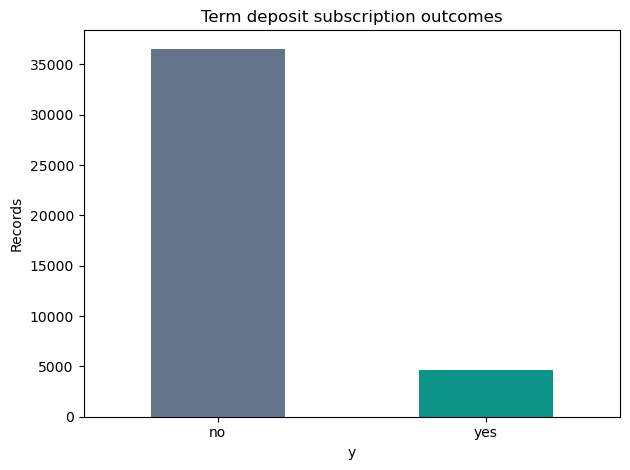

In [238]:
counts = df.y.value_counts().reindex(['no','yes'])
counts.plot.bar(color=['#64748b','#0d9488'], rot=0, title='Term deposit subscription outcomes')
plt.ylabel('Records'); plt.tight_layout(); plt.show()


#### Observation:
- There are categorical and numeric features in the data set.
- The dataset also contains missing information represented by the string
'unknown' in several categorical columns.
- Categorical features will require encoding. 
- Numeric features should be scaled.
- Class imbalance, majority non subscribers.

### Problem 4: Understanding the Task

After examining the description and data, your goal now is to clearly state the *Business Objective* of the task.  State the objective below.

The business objective is to improve the effectiveness and efficiency
of the bank's telephone marketing campaigns by identifying clients
who are more likely to subscribe to a term deposit.

The machine learning task is binary classification, with the target
variable y indicating whether a client subscribed ('yes') or did not
subscribe ('no').

The model should support prioritizing clients before making calls,
aiming to increase subscriptions per call and reduce unsuccessful
contacts. 

We will compare KNN, Logistic Regression, Decision Tree, and SVM
using predictive performance and training time. Alongside accuracy,
we will examine precision and recall to understand unsuccessful
targeting and missed subscribers.

### Problem 5: Engineering Features

Now that you understand your business objective, we will build a basic model to get started.  Before we can do this, we must work to encode the data.  Using just the bank information features, prepare the features and target column for modeling with appropriate encoding and transformations.


The target is encoded as yes = 1 and no = 0. 

In [209]:
feature_columns = [
    'age',
    'job',
    'marital',
    'education',
    'default',
    'housing',
    'loan'
]

# Inputs used to make predictions
X = df[feature_columns].copy()

# Outcome we want to predict
y = df['y'].map({'no': 0, 'yes': 1})

print("Feature shape:", X.shape)
print("Target shape:", y.shape)

Feature shape: (41188, 7)
Target shape: (41188,)


We set up a preprocessing pipeline that:
- imputes missing numeric values with the median and standardizes numeric features
- imputes missing categorical values with the most frequent value and one-hot encodes categories

This ensures a fair comparison across models (especially for KNN and SVM which are sensitive to feature scale).

In [210]:

numeric_features = ['age']

categorical_features = [
    'job',
    'marital',
    'education',
    'default',
    'housing',
    'loan'
]

preprocessor = ColumnTransformer([
    ('age', Pipeline([('impute', SimpleImputer(strategy='median')),
                      ('scale', StandardScaler())]), numeric_features),
    ('category', Pipeline([('impute', SimpleImputer(strategy='most_frequent')),
                          ('encode', OneHotEncoder(handle_unknown='ignore', sparse_output=False))]), categorical_features)
])

### Problem 6: Train/Test Split

With your data prepared, split it into a train and test set.

We split data with 80-20 rule with stratify = y
80% Training
20% Test

In [ ]:


X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

In [212]:
#Check sizes
print("Training features:", X_train.shape)
print("Testing features:", X_test.shape)
print("Training target:", y_train.shape)
print("Testing target:", y_test.shape)

Training features: (32950, 7)
Testing features: (8238, 7)
Training target: (32950,)
Testing target: (8238,)


In [213]:
split_summary = pd.DataFrame({
    'Dataset': ['Full dataset', 'Training', 'Test'],
    'Records': [len(y), len(y_train), len(y_test)],
    'Subscription rate (%)': [
        y.mean() * 100,
        y_train.mean() * 100,
        y_test.mean() * 100
    ]
})

split_summary.round(2)

,Dataset,Records,Subscription rate (%)
0,Full dataset,41188,11.27
1,Training,32950,11.27
2,Test,8238,11.26


The data is divided into 80% training and 20% testing. Stratification preserves
approximately the same subscription rate in both partitions.

### Problem 7: A Baseline Model

Before we build our first model, we want to establish a baseline.  What is the baseline performance that our classifier should aim to beat?

We will start with KNN as baseline model

In [214]:
knn_pipe = Pipeline(steps=[
    ("preprocess", preprocessor),
    ("model", KNeighborsClassifier(n_neighbors=15))
])

knn_pipe.fit(X_train, y_train)
knn_pred = knn_pipe.predict(X_test)
knn_proba = knn_pipe.predict_proba(X_test)[:, 1]

print("KNN (test):")
print("Accuracy:", accuracy_score(y_test, knn_pred))
print("Precision:", precision_score(y_test, knn_pred, zero_division=0))
print("Recall:", recall_score(y_test, knn_pred, zero_division=0))
print("F1:", f1_score(y_test, knn_pred, zero_division=0))
print("ROC-AUC:", roc_auc_score(y_test, knn_proba))

k_used = knn_pipe.named_steps["model"].n_neighbors
print(f"K used in KNN: {k_used}")


KNN (test):
Accuracy: 0.8869871327992231
Precision: 0.48148148148148145
Recall: 0.04202586206896552
F1: 0.07730426164519326
ROC-AUC: 0.6220022907920184
K used in KNN: 15


### Problem 8: A Simple Model

Use Logistic Regression to build a basic model on your data.  

Using Logistic Regression

In [239]:

from time import perf_counter

logistic_model = Pipeline(steps=[
    ("preprocess", preprocessor),
    ("model", LogisticRegression(max_iter=2000, random_state=42))
])

start_time = perf_counter()
logistic_model.fit(X_train, y_train)
logistic_train_time = perf_counter() - start_time

print(f"Training time: {logistic_train_time:.4f} seconds")
baseline_pred = logistic_model.predict(X_test)
baseline_proba = logistic_model.predict_proba(X_test)[:, 1]

baseline_train_pred = logistic_model.predict(X_train)
baseline_train_proba = logistic_model.predict_proba(X_train)[:, 1]



Training time: 0.1617 seconds


### Problem 9: Score the Model

What is the accuracy of your model?

In [241]:

print("Logistic Regression (test):")
print("Accuracy:", accuracy_score(y_test, baseline_pred))
print("Precision:", precision_score(y_test, baseline_pred,zero_division=0))
print("Recall:", recall_score(y_test, baseline_pred))
print("F1:", f1_score(y_test, baseline_pred, zero_division=0))
print("ROC-AUC:", roc_auc_score(y_test, baseline_proba))


Logistic Regression (test):
Accuracy: 0.8873512988589464
Precision: 0.0
Recall: 0.0
F1: 0.0
ROC-AUC: 0.6491506822255766


Logistic Regression achieves approximately 88.74% test accuracy.

### Problem 10: Model Comparisons

Now, we aim to compare the performance of the Logistic Regression model to our KNN algorithm, Decision Tree, and SVM models.  Using the default settings for each of the models, fit and score each.  Also, be sure to compare the fit time of each of the models.  Present your findings in a `DataFrame` similar to that below:

| Model | Train Time | Train Accuracy | Test Accuracy |
| ----- | ---------- | -------------  | -----------   |
|     |    |.     |.     |

We compare KNN, Logistic Regression, Decision Tree, and SVM.

In [ ]:
models = {
    'Logistic Regression': LogisticRegression(max_iter=1000),
    'KNN': KNeighborsClassifier(),
    'Decision Tree': DecisionTreeClassifier(random_state=42),
    'SVM': SVC()
}


results = []
trained_models = {}

for name, model in models.items():
    print(f"Training {name}...")

    model_pipeline = Pipeline([
        ('preprocessor', clone(preprocessor)),
        ('classifier', clone(model))
    ])

    # Measure training time
    start_time = perf_counter()
    model_pipeline.fit(X_train, y_train)
    train_time = perf_counter() - start_time

    # Generate predictions
    train_predictions = model_pipeline.predict(X_train)
    test_predictions = model_pipeline.predict(X_test)

    # Save results
    results.append({
        'Model': name,
        'Train Time (seconds)': train_time,
        'Train Accuracy': accuracy_score(y_train, train_predictions),
        'Test Accuracy': accuracy_score(y_test, test_predictions),
        'Precision': precision_score(y_test, test_predictions, zero_division=0),
        'Recall': recall_score(y_test, test_predictions, zero_division=0),
        'F1': f1_score(y_test, test_predictions, zero_division=0)
    })

    trained_models[name] = model_pipeline

comparison_df = pd.DataFrame(results).set_index('Model')
comparison_df.round(4)

Training Logistic Regression...
Training KNN...
Training Decision Tree...
Training SVM...


,Train Time (seconds),Train Accuracy,Test Accuracy,Precision,Recall,F1
Model,,,,,,
Logistic Regression,0.1346,0.8873,0.8874,0.0000,0.0000,0.0000
KNN,0.0500,0.8917,0.8803,0.3564,0.0776,0.1274
Decision Tree,0.0866,0.9171,0.8645,0.2283,0.0851,0.1240
SVM,14.6584,0.8882,0.8864,0.2778,0.0054,0.0106


Logistic Regression achieved the highest test accuracy of 88.73%,
but its subscriber recall and F1 were zero. Its accuracy therefore
does not demonstrate useful subscriber detection.

KNN achieved the highest precision (35.64%) and F1 score (0.1274),
although its recall of 7.76% indicates that most subscribers were
missed.

The Decision Tree achieved the highest recall (8.51%), but its
training accuracy of 91.71% versus test accuracy of 86.45% suggests
overfitting.

SVM required the longest training time, approximately 14.80 seconds,
while achieving only 0.54% subscriber recall.

### Problem 11: Improving the Model

Now that we have some basic models on the board, we want to try to improve these.  Below, we list a few things to explore in this pursuit.


- Hyperparameter tuning and grid search.  All of our models have additional hyperparameters to tune and explore.  For example the number of neighbors in KNN or the maximum depth of a Decision Tree.  
- Adjust your performance metric

Tune all four classifiers using the same stratified cross-validation folds.
Select hyperparameters by mean validation F1 for class 1—subscribers.

In [ ]:
cv = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

#Define models and hyperparameter grids
param_grids = {
    "KNN": {
        "model__n_neighbors": [5, 11, 15, 25],
        "model__weights": ["uniform", "distance"]
    },
    "Logistic Regression": {
        "model__C": [0.1, 1.0, 5.0, 10.0],
        "model__penalty": ["l2"],
        "model__solver": ["lbfgs"],
        "model__class_weight": [None, "balanced"]
    },
    "Decision Tree": {
        "model__max_depth": [None, 3, 5, 10],
        "model__min_samples_split": [2, 10, 30],
        "model__min_samples_leaf": [1, 5, 10],
        "model__class_weight": [None, "balanced"]
    },
    "SVM": {
        "model__C": [0.5, 1.0, 5.0, 10.0],
        "model__gamma": ["scale", 0.1, 0.01],
        "model__class_weight": [None, "balanced"]
    }
}

#Store searches, fitted models, and detailed results
searches = {}
best_models = {}
tuning_rows = []

for name, model in models.items():
    print(f"Tuning {name}...", flush=True)
    pipe = Pipeline(steps=[("preprocess", clone(preprocessor)), ("model", clone(model))])
    grid = GridSearchCV(pipe, param_grids[name], scoring="f1", cv=cv, n_jobs=-1)
    start = perf_counter()
    grid.fit(X_train, y_train)
    elapsed = perf_counter() - start
    searches[name] = grid
    best_models[name] = grid.best_estimator_
    tuning_rows.append({
        "model": name, 
        "best_f1_cv": grid.best_score_, 
        "best_params": grid.best_params_,
        "search_seconds": elapsed
        })

tuning_df = pd.DataFrame(tuning_rows).sort_values("best_f1_cv", ascending=False).reset_index(drop=True)
display(tuning_df)

#Select the model with the by CV F1 only
best_model_name = tuning_df.loc[0, "model"]
best_model = best_models[best_model_name]

print("Selected model:", best_model_name)
print("Best parameters:", searches[best_model_name].best_params_)

Tuning Logistic Regression...


0.00s - Debugger warning: It seems that frozen modules are being used, which may
0.00s - make the debugger miss breakpoints. Please pass -Xfrozen_modules=off
0.00s - to python to disable frozen modules.
0.00s - Note: Debugging will proceed. Set PYDEVD_DISABLE_FILE_VALIDATION=1 to disable this validation.
0.00s - Debugger warning: It seems that frozen modules are being used, which may
0.00s - make the debugger miss breakpoints. Please pass -Xfrozen_modules=off
0.00s - Debugger warning: It seems that frozen modules are being used, which may
0.00s - to python to disable frozen modules.
0.00s - make the debugger miss breakpoints. Please pass -Xfrozen_modules=off
0.00s - Note: Debugging will proceed. Set PYDEVD_DISABLE_FILE_VALIDATION=1 to disable this validation.
0.00s - to python to disable frozen modules.
0.00s - Note: Debugging will proceed. Set PYDEVD_DISABLE_FILE_VALIDATION=1 to disable this validation.
0.00s - Debugger warning: It seems that frozen modules are being used, which may
0

Tuning KNN...


199859.50s - pydevd: Sending message related to process being replaced timed-out after 5 seconds
0.00s - Debugger warning: It seems that frozen modules are being used, which may
0.00s - make the debugger miss breakpoints. Please pass -Xfrozen_modules=off
0.00s - to python to disable frozen modules.
0.00s - Note: Debugging will proceed. Set PYDEVD_DISABLE_FILE_VALIDATION=1 to disable this validation.


Tuning Decision Tree...
Tuning SVM...


,model,best_f1_cv,best_params,search_seconds
0,SVM,0.262676,"{'model__C': 0.5, 'model__class_weight': 'bala...",260.775082
1,Logistic Regression,0.255636,"{'model__C': 1.0, 'model__class_weight': 'bala...",3.517837
2,Decision Tree,0.252478,"{'model__class_weight': 'balanced', 'model__ma...",2.933074
3,KNN,0.142829,"{'model__n_neighbors': 5, 'model__weights': 'd...",3.042100


Selected model: SVM
Best parameters: {'model__C': 0.5, 'model__class_weight': 'balanced', 'model__gamma': 'scale'}


Hyperparameter tuning selected SVM by the highest mean CV subscriber F1. 

#### Evaluate tuned models on the test set

In [250]:

# Evaluate tuned models on the test set
test_rows = []
for name, est in best_models.items():
    pred = est.predict(X_test)
    test_rows.append({
        "model": f"Tuned {name}",
        "accuracy": accuracy_score(y_test, pred),
        "precision": precision_score(y_test, pred, zero_division=0),
        "recall": recall_score(y_test, pred, zero_division=0),
        "f1": f1_score(y_test, pred, zero_division=0),
    })

test_df = pd.DataFrame(test_rows).sort_values("f1", ascending=False).reset_index(drop=True)
test_df

,model,accuracy,precision,recall,f1
0,Tuned Decision Tree,0.650158,0.170155,0.543103,0.259126
1,Tuned SVM,0.604637,0.164119,0.613147,0.258931
2,Tuned Logistic Regression,0.584365,0.158082,0.621767,0.252075
3,Tuned KNN,0.870842,0.286164,0.098060,0.146067


SVM achieved the highest cross-validation F1, while Decision Tree and SVM performed almost identically on test F1.

,Train F1,Test F1,Test Precision,Test Recall,Test Accuracy,Test Balanced Accuracy
Model,,,,,,
SVM,0.2796,0.2589,0.1641,0.6131,0.6046,0.6084


,Predicted No,Predicted Yes
Actual No,4412,2898
Actual Yes,359,569


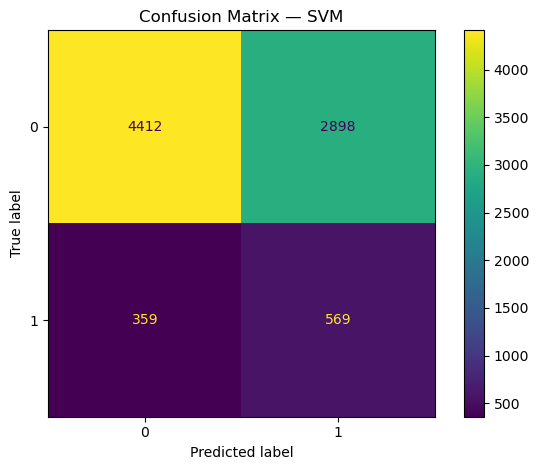

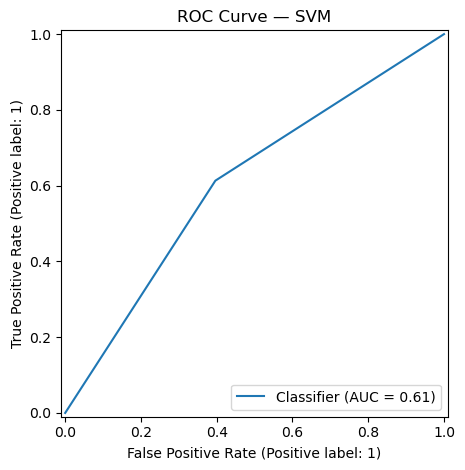


Classification report:
              precision    recall  f1-score   support

           0       0.92      0.60      0.73      7310
           1       0.16      0.61      0.26       928

    accuracy                           0.60      8238
   macro avg       0.54      0.61      0.49      8238
weighted avg       0.84      0.60      0.68      8238



In [ ]:
best_model = best_models[best_model_name]

train_predictions = best_model.predict(X_train)
test_predictions = best_model.predict(X_test)


evaluation = pd.DataFrame([{
    "Model": best_model_name,
    "Train F1": f1_score(
        y_train, train_predictions, zero_division=0
    ),
    "Test F1": f1_score(
        y_test, test_predictions, zero_division=0
    ),
    "Test Precision": precision_score(
        y_test, test_predictions, zero_division=0
    ),
    "Test Recall": recall_score(
        y_test, test_predictions, zero_division=0
    ),
    "Test Accuracy": accuracy_score(
        y_test, test_predictions
    ),
    "Test Balanced Accuracy": balanced_accuracy_score(
        y_test, test_predictions
    )
}]).set_index("Model")

display(evaluation.round(4))

display(pd.DataFrame(
    confusion_matrix(y_test, test_predictions, labels=[0, 1]),
    index=["Actual No", "Actual Yes"],
    columns=["Predicted No", "Predicted Yes"]
))

ConfusionMatrixDisplay.from_predictions(y_test, test_predictions, values_format="d")
plt.title(f"Confusion Matrix — {best_model_name}")
plt.tight_layout()
plt.show()

RocCurveDisplay.from_predictions(y_test, test_predictions)
plt.title(f"ROC Curve — {best_model_name}")
plt.tight_layout()
plt.show()

print("\nClassification report:")
print(classification_report(y_test, test_predictions, zero_division=0))

Conclusion:
- Selected model: SVM with C=0.5
- Test F1: 0.2589.
- Main improvement: Detects 61.31% of subscribers.
- Main limitation: Precision is only 16.41%, meaning many false positives.

On the test set, it achieved F1 of 0.2589, precision of 16.41%, and recall of 61.31%. It correctly identified 569 of 928 subscribers, while generating 2,898 false positives.

##### Questions